# PILEX

Data-science programs written in symbols, with what they print and draw. Each code cell is a program in symbols; under it is what it produced (tables are shown as text, and a chart is shown where it was drawn).

This notebook shows the programs and their results. The program that runs the symbols is not part of this repository.

## The symbols

| Symbol | What it does | Why this sign |
|---|---|---|
| **Bring data in, send it out** | | |
| `↓?` | ask you for a file (upload) | ↓ brings a file in, ? asks you which one |
| `↓` | bring a table in from a file | arrow down: bring a file in |
| `✎` | make a ready-made practice table | a pencil: practice |
| `↑` | save a table to a file | arrow up: send a file out |
| **Look at it** | | |
| `^` | show the first rows of a table | ^ means the start (in search patterns and in the vi editor) |
| `μσ` | describe every column of a table | mean and spread: the textbook way to describe a table |
| `σ` | summary of a list or of one column | spread: a one-line summary of a list or a column |
| `ρ` | how strongly two columns are linked | rho: correlation, how strongly two things move together |
| `μ` | average of some columns for each group | mu: the mean |
| `Σ` | add up an amount for each month | sigma: the sum |
| `¶▲` | most common words in a text column | ¶ is text, ▲ is the peak: the most common |
| **Clean it** | | |
| `✨` | tidy a list or a table in one step | a sparkle: make it tidy |
| `∅` | fill empty cells in some columns | the empty set: fill what is empty |
| `✂` | cut out rows with an extreme value in a column | scissors: trim the extremes |
| `▯` | drop columns that are mostly empty | an empty column |
| `▮` | drop columns with the same value in every row | a solid column: every value the same |
| `≡` | drop rows that appear twice | identical to: rows that are the same |
| **Prepare** | | |
| `⌚` | read a column as dates, with the shape written as d m y H M S, for example "d/m/y" | a watch: these are dates and times |
| **Learn and guess** | | |
| `θ` | teach a model to guess one column from other columns | theta: the numbers a model learns |
| `θ¶` | teach a model to sort texts | a model (θ) for text (¶) |
| `κ` | sort rows into k groups of similar rows | kappa is the Greek k: k groups (k-means) |
| `⇅` | rank the inputs by how much they matter | sort arrows: put in order of importance |
| `✓` | check a model on rows it has not seen | a tick: check it |
| `✓✗` | show where a model is right and where it is wrong | ticks and crosses |
| `ŷ` | guess for new values | y-hat: the predicted value |
| **Draw** | | |
| `█` | histogram | bars |
| `◔` | pie chart | a pie |
| `⊟` | box plot of a column for each group | a box with its middle line |
| `╱` | dots with the line that fits them best | a straight line |
| `▦` | map of the links between the number columns | a grid of shades |
| `•` | dots of two columns, coloured by group if one is given | dots |
| `~` | line chart | a wavy line |
| **One-line recipes** | | |
| `⚡§` | a whole report of a table in one line | ⚡ quick + § a report |
| `⚡ŷ` | a whole guess in one line: clean a copy, try two models, keep the better | ⚡ quick + ŷ predict |
| **Choices written as symbols** | | |
| `μ` | fill empty cells with the average | the mean |
| `½` | fill empty cells with the middle value | the half-way value (the median) |
| `▲` | fill empty cells with the most common value | the peak (the mode) |
| `╱` | a straight line model | a straight line |
| `⋔` | a decision tree model | a fork: a tree of questions |
| `⋔⋔` | a random forest model | many forks: many trees |
| `ℝ` | the answer is a number | the real numbers |
| `∈` | the answer is a class (a label) | belongs to a set of labels |

34 command symbols: 17 are signs that already carry this meaning (mathematics, statistics, everyday screen icons), 12 are small pictures of the thing, and 5 are new choices. The signs μ and ╱ are in the table twice: at the start of a line they are commands, and in the place of a value they are choices.

## 01. A full study of exam marks: look, clean, draw, find the link, guess

Loaded 40 rows and 7 columns from marks.csv.
The first 3 of 40 rows of marks:
  class  year study_hours sleep_hours  attendance  score result
0     A  2025         8.4         5.9          91     77   pass
1     B  2025         6.3         6.6          93     60   pass
2     C  2025         7.9         7.9          97     74   pass
marks: 40 rows and 7 columns.
     column    kind  missing smallest biggest average
      class   words        0                         
       year numbers        0     2025    2025    2025
study_hours numbers        2        1     9.5    5.56
sleep_hours numbers        0      4.5     8.8    6.63
 attendance numbers        0       64     100   84.12
      score numbers        0       23     999   80.15
     result   words        0                         
Filled 2 gaps in study_hours with the middle value (5.95).
Removed 1 row where score is far from the rest (999).
No column is more than 50% empty.
Removed the column year: it is the same on every row.
No 

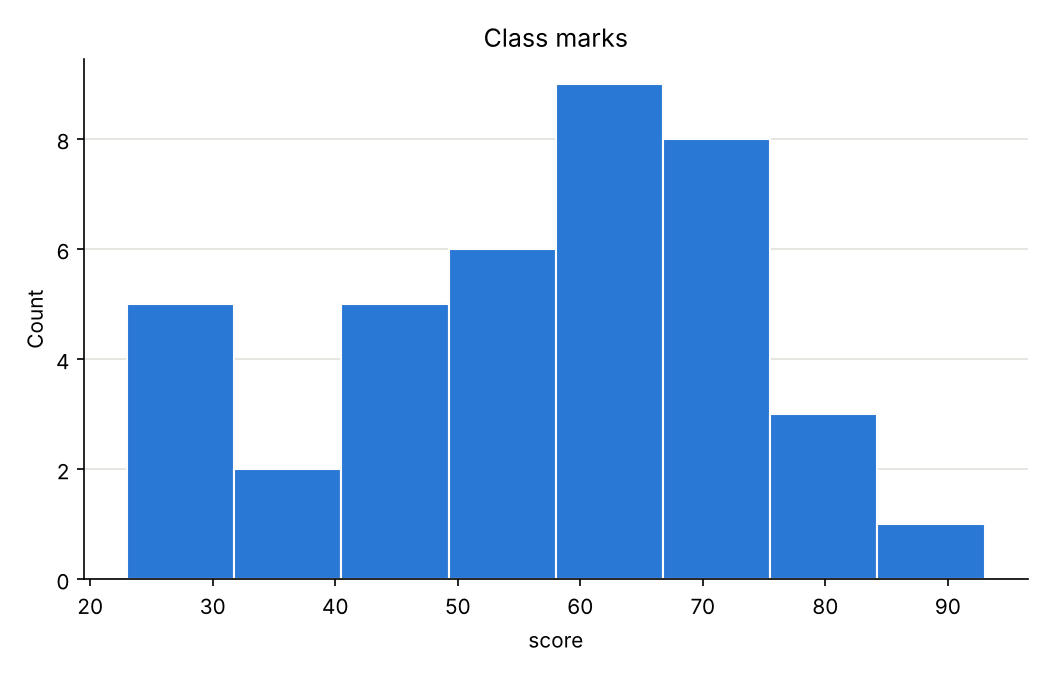

Drawing a pie chart of result.


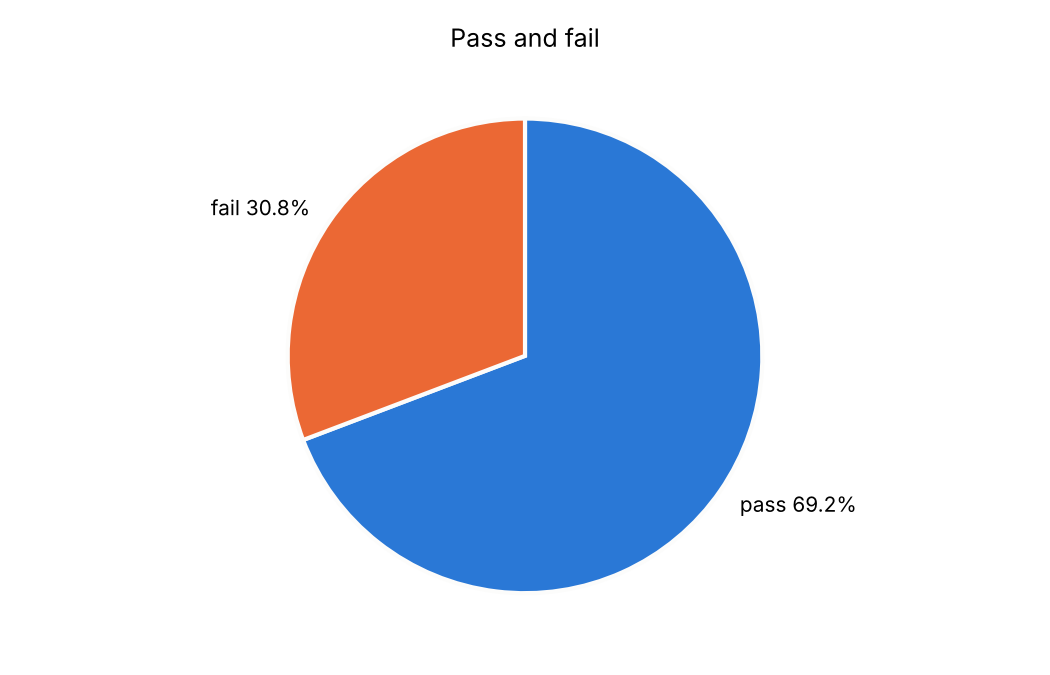

Drawing the links between the number columns of marks.


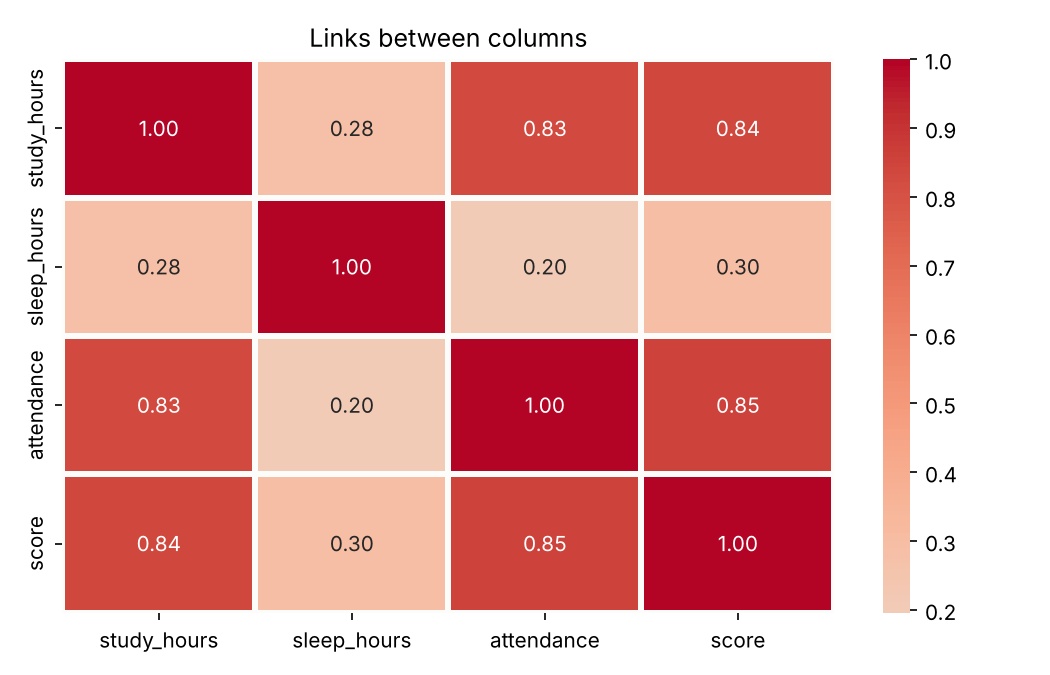

Drawing the dots of study_hours and score, with the line that fits them best.


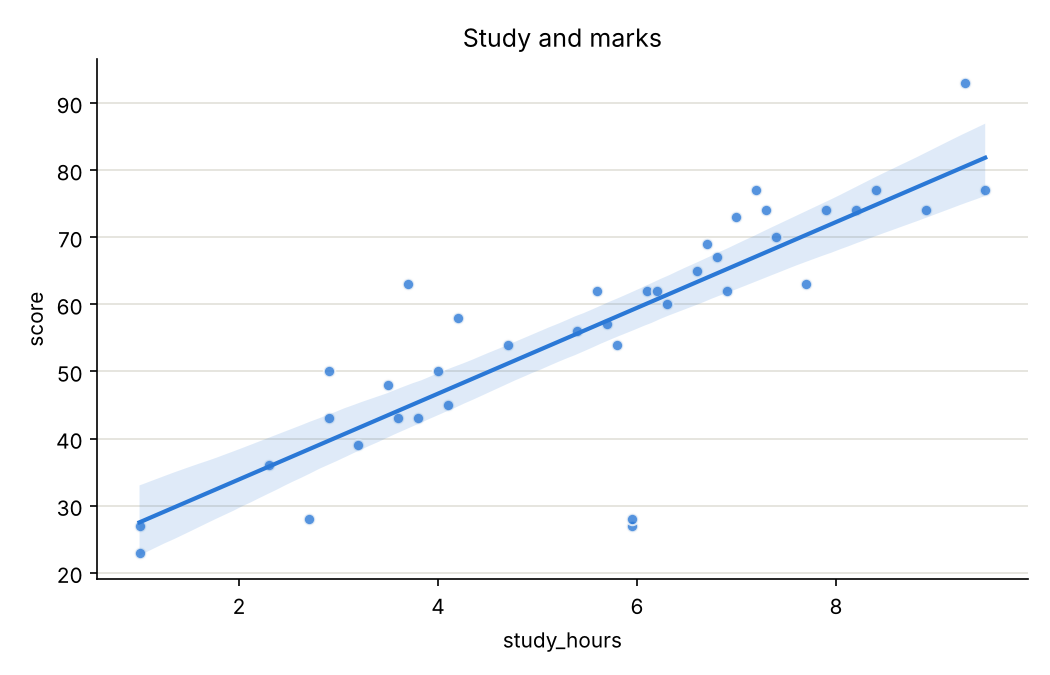

study_hours and score: link 0.84, a strong upward link. When study_hours is higher, score tends to be higher. A link does not prove that one causes the other.
The answer "score" is a number with many different values, so I guess a number.
Taught a straight line on 31 rows and tested it on 8 others.
On average the guess for score is off by 2.83.
The model explains 89% of the ups and downs in score.
For study_hours 6 and sleep_hours 7 the guess is 59.8.


In [1]:
%%sym
marks ← ↓ "marks.csv"
^ marks, 3
μσ marks
marks ← ∅ marks, "study_hours", ½
marks ← ✂ marks, "score"
marks ← ▯ marks
marks ← ▮ marks
marks ← ≡ marks
█ marks, "score", 8, "Class marks"
◔ marks, "result", "Pass and fail"
▦ marks, "Links between columns"
╱ marks, "study_hours", "score", "Study and marks"
ρ marks, "study_hours", "score"
inputs ← ["study_hours", "sleep_hours"]
m ← θ marks, inputs, "score", ╱
✓ m
ŷ m, [6, 7]

## 02. Will a student pass? Rank the inputs, teach a forest, sort rows into groups

Loaded 40 rows and 7 columns from marks.csv.
Filled 2 gaps in study_hours with the average (5.56).
Removed 1 row where score is far from the rest (999).
Removed the column year: it is the same on every row.
Cleaned marks: 40 rows and 7 columns became 39 rows and 6 columns.
The answer "score" is a number with many different values, so I guess a number.
Ranked 3 columns for guessing score: study_hours matters most. A high share means the guesses lean on that column, not that it causes the answer.
     column  share (%)
study_hours         69
 attendance         25
sleep_hours          6
The answer "result" holds words, so I guess a class: fail or pass.
Taught a random forest on 31 rows and tested it on 8 others.
It was right for 8 of 8.
When it said fail, it was right 2 times out of 2.
Of the rows that really were fail, it found 2 out of 2.
When it said pass, it was right 6 times out of 6.
Of the rows that really were pass, it found 6 out of 6.
Each row is what the test rows really were,

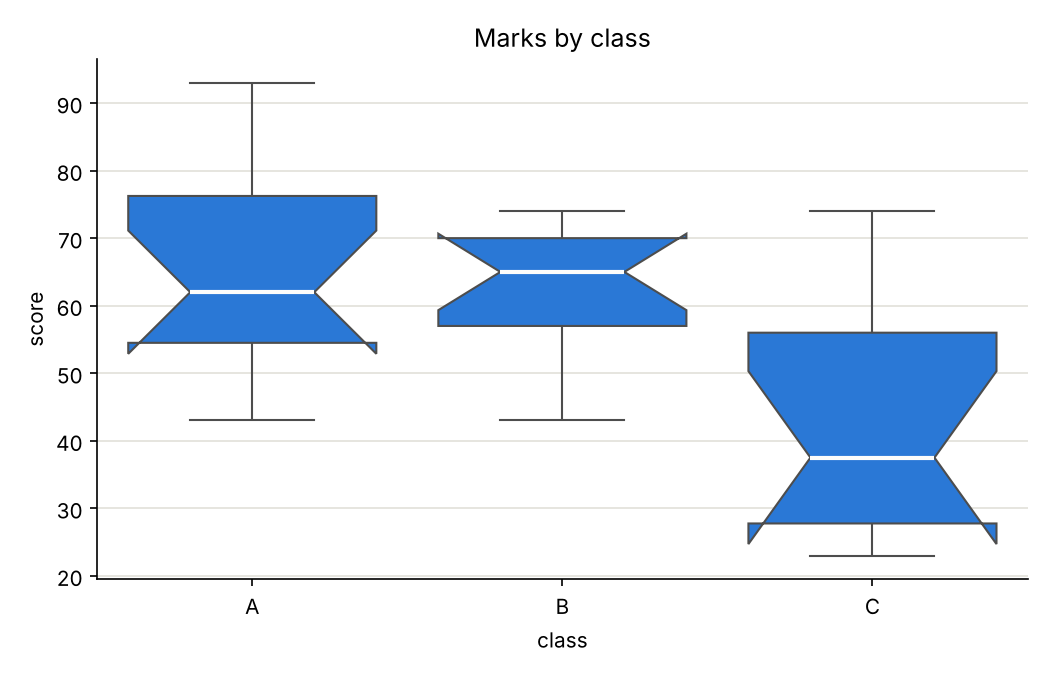

Sorted 39 rows into 3 groups, numbered from the lowest study_hours to the highest.
Grouped groups by group: 3 groups, the highest average study_hours first.
 group  rows average study_hours average sleep_hours average score
     3    16                7.59                6.51          71.5
     2    15                4.91                7.27         52.07
     1     8                2.56                5.44         35.25
Drawing dots of study_hours and score.


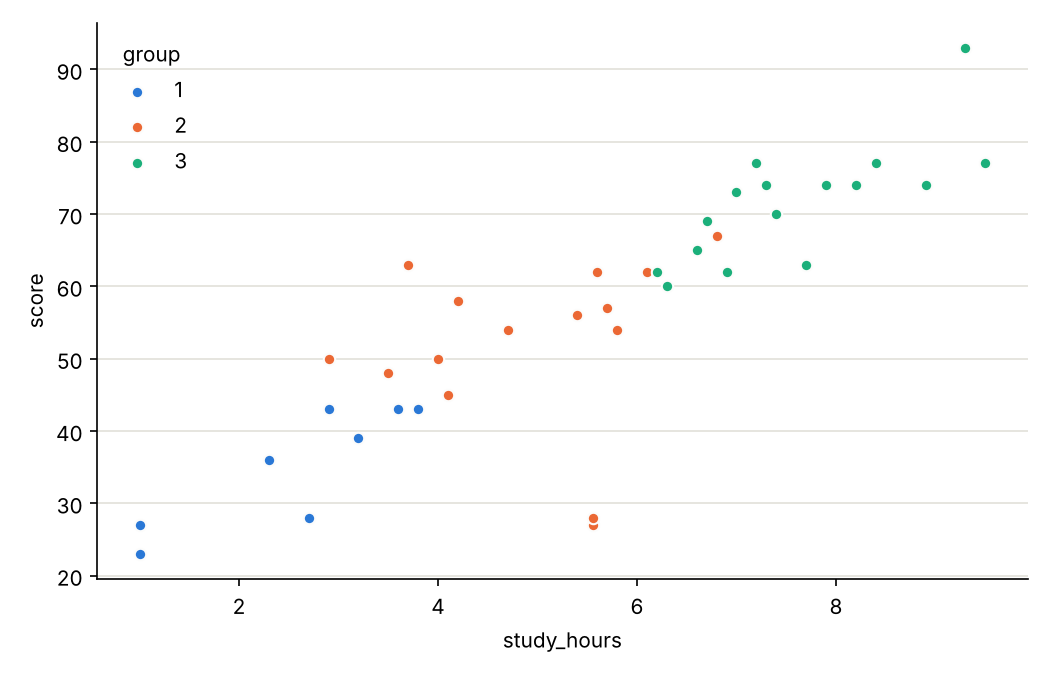

In [2]:
%%sym
marks ← ↓ "marks.csv"
marks ← ✨ marks
inputs ← ["study_hours", "sleep_hours", "attendance"]
⇅ marks, inputs, "score"
m ← θ marks, inputs, "result", ⋔⋔, ∈
✓ m
✓✗ m
ŷ m, [7, 6, 90]
⊟ marks, "class", "score", "Marks by class"
groups ← κ marks, ["study_hours", "sleep_hours", "score"], 3
μ groups, "group", ["study_hours", "sleep_hours", "score"]
• groups, "study_hours", "score", "group"

## 03. Sales added up by month, and good or bad reviews

Loaded 240 rows and 2 columns from sales.csv.
Read 240 dates in the column date.
Added up amount for each month: 12 months, from 2025-01 to 2025-12.
Drawing a line of total against month.


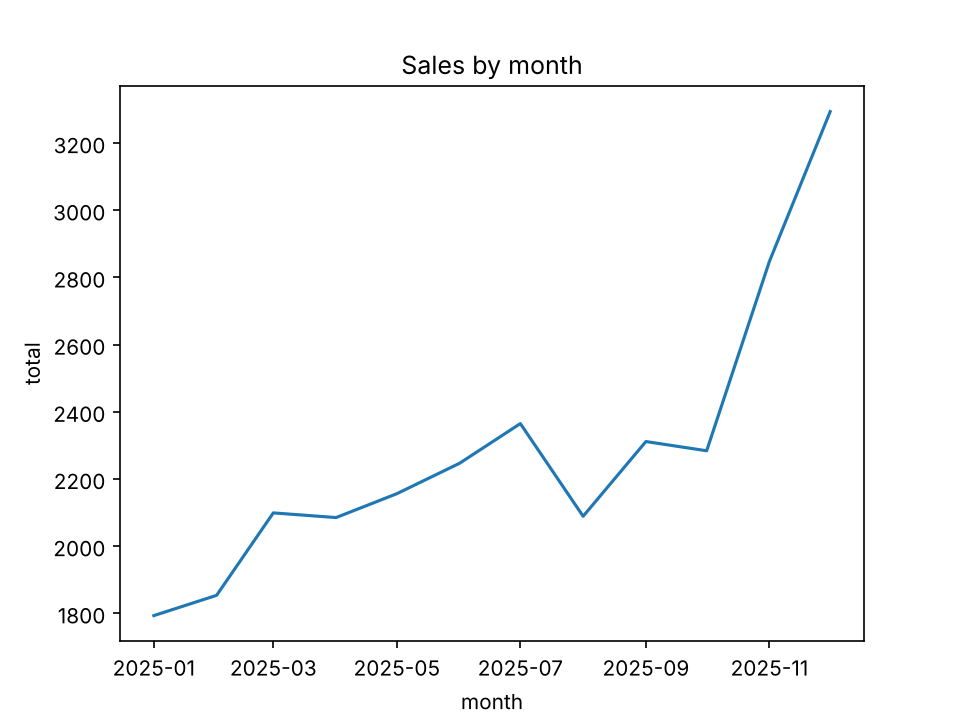

Saved 12 rows and 2 columns to months.csv.
Loaded 40 rows and 2 columns from reviews.csv.
The 5 words used most often in text. Very common words such as the and a are left out.
    word  count
honestly      8
   place      7
  lovely      6
    come      6
    meal      5
Taught a text sorter on 32 rows and tested it on 8 others.
It was right for 7 of 8.
When it said bad, it was right 3 times out of 3.
Of the rows that really were bad, it found 3 out of 4.
When it said good, it was right 4 times out of 5.
Of the rows that really were good, it found 4 out of 4.
For "Cold food and rude staff" the guess is bad.


In [3]:
%%sym
sales ← ↓ "sales.csv"
sales ← ⌚ sales, "date", "d/m/y"
months ← Σ sales, "date", "amount"
~ months, "month", "total", "Sales by month"
↑ months, "months.csv"

reviews ← ↓ "reviews.csv"
¶▲ reviews, "text", 5
m ← θ¶ reviews, "text", "label"
✓ m
ŷ m, "Cold food and rude staff"

## 04. What is in this file?

In [4]:
%%sym
marks ← ↓ "marks.csv"
^ marks, 5
μσ marks

Loaded 40 rows and 7 columns from marks.csv.
The first 5 of 40 rows of marks:
  class  year study_hours sleep_hours  attendance  score result
0     A  2025         8.4         5.9          91     77   pass
1     B  2025         6.3         6.6          93     60   pass
2     C  2025         7.9         7.9          97     74   pass
3     A  2025         7.2         7.2          85     77   pass
4     B  2025           7           8          93     73   pass
marks: 40 rows and 7 columns.
     column    kind  missing smallest biggest average
      class   words        0                         
       year numbers        0     2025    2025    2025
study_hours numbers        2        1     9.5    5.56
sleep_hours numbers        0      4.5     8.8    6.63
 attendance numbers        0       64     100   84.12
      score numbers        0       23     999   80.15
     result   words        0                         


## 05. A typed list with one typing mistake

In [5]:
%%sym
scores ← ✨ [56, 54, 62, 48, 999, 58, 61, 55]
σ scores

Removed 1 value that is far from the rest: 999.
7 numbers. Smallest 48, biggest 62, average 56.3, middle value 56.


## 06. A whole file with gaps, a wrong value and a useless column

In [6]:
%%sym
marks ← ↓ "marks.csv"
marks ← ∅ marks, "study_hours", μ
marks ← ✂ marks, "score"
marks ← ▯ marks
marks ← ▮ marks
marks ← ≡ marks
↑ marks, "marks_clean.csv"

Loaded 40 rows and 7 columns from marks.csv.
Filled 2 gaps in study_hours with the average (5.56).
Removed 1 row where score is far from the rest (999).
No column is more than 50% empty.
Removed the column year: it is the same on every row.
No row appears twice.
Saved 39 rows and 6 columns to marks_clean.csv.


## 07. The shape of the data in three charts

Loaded 39 rows and 6 columns from marks_clean.csv.
Drawing a histogram of score in 8 bars.


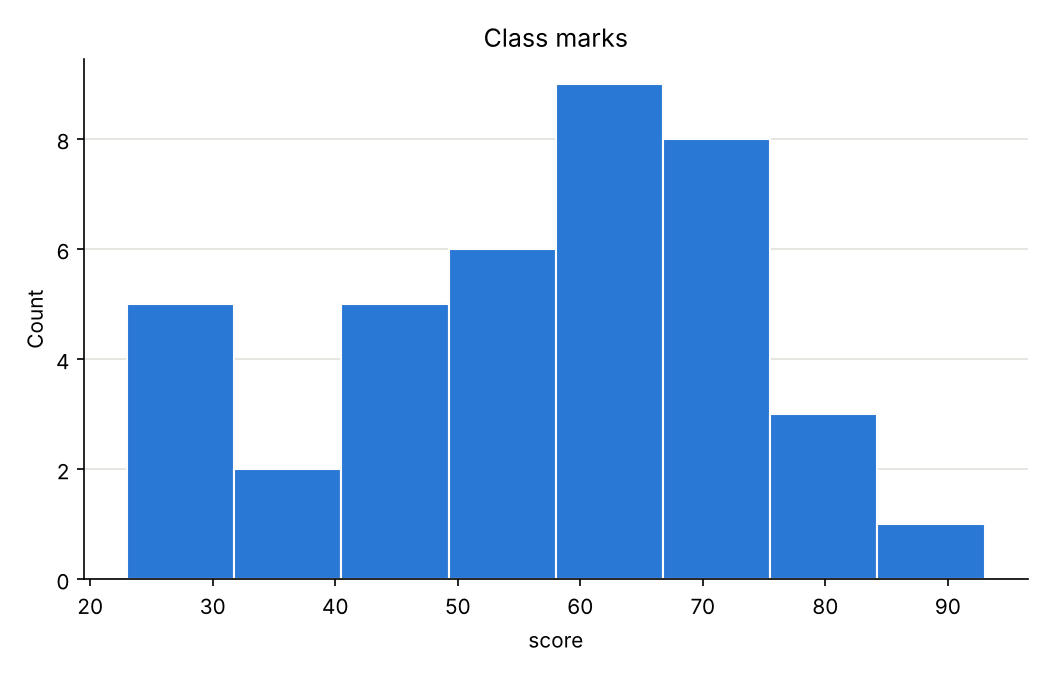

Drawing a pie chart of result.


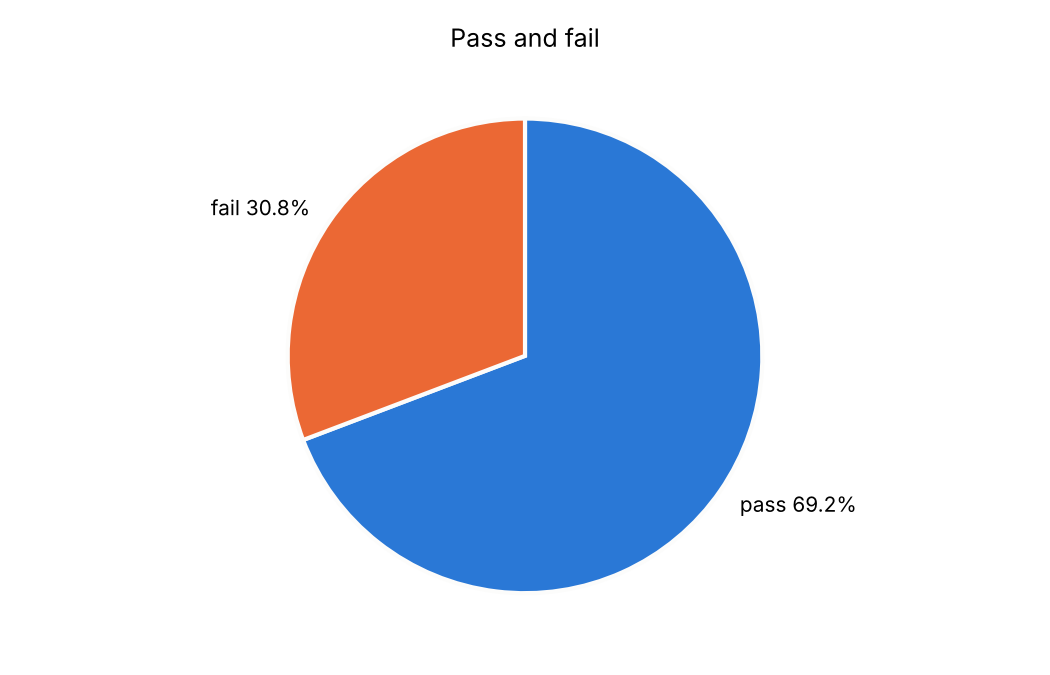

Drawing the links between the number columns of marks.


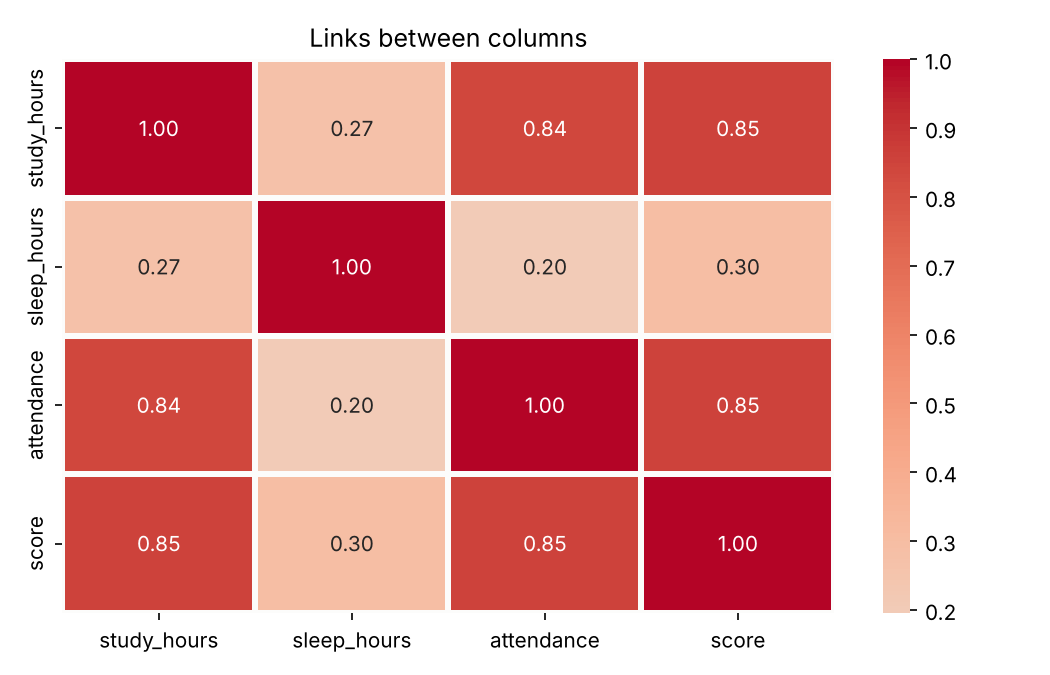

In [7]:
%%sym
marks ← ↓ "marks_clean.csv"
█ marks, "score", 8, "Class marks"
◔ marks, "result", "Pass and fail"
▦ marks, "Links between columns"

## 08. Which class does best?

Loaded 39 rows and 6 columns from marks_clean.csv.
Grouped marks by class: 3 groups, the highest average score first.
class  rows average score
    A    14         63.64
    B    13            62
    C    12          42.5
Drawing box plots of score for each class.


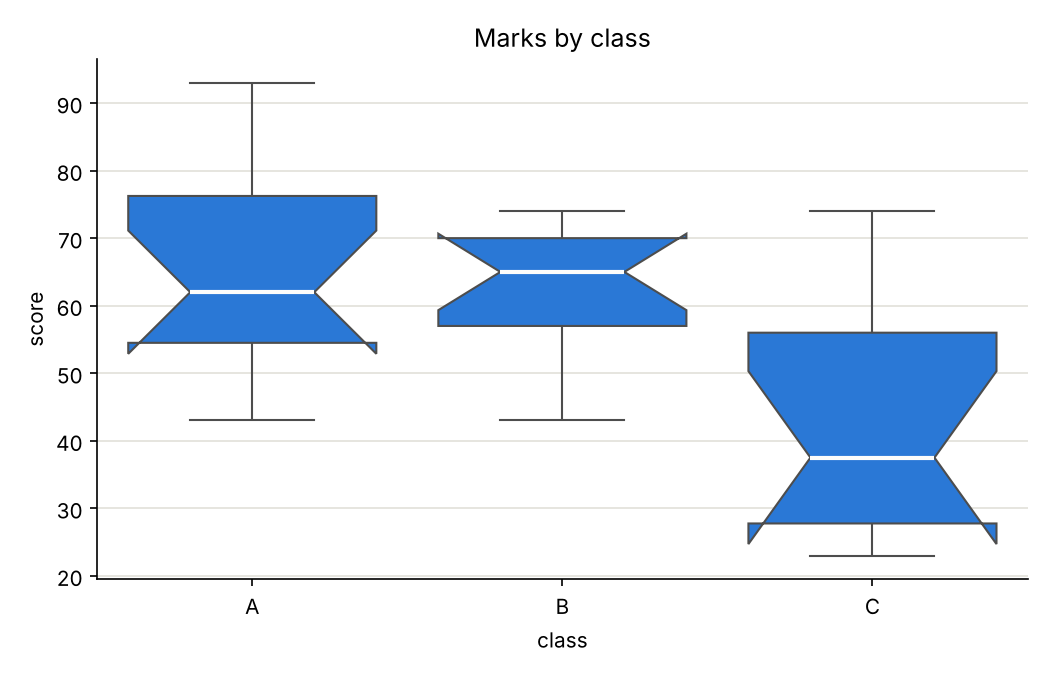

In [8]:
%%sym
marks ← ↓ "marks_clean.csv"
μ marks, "class", "score"
⊟ marks, "class", "score", "Marks by class"

## 09. Do students who study more get better marks?

Loaded 39 rows and 6 columns from marks_clean.csv.
Drawing the dots of study_hours and score, with the line that fits them best.


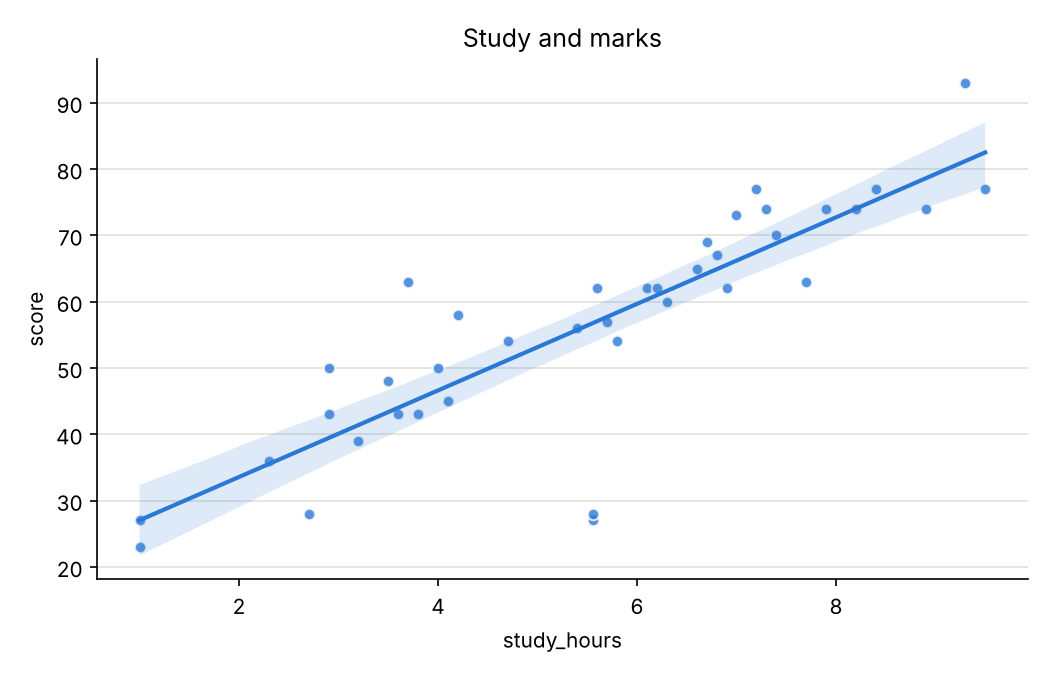

study_hours and score: link 0.85, a strong upward link. When study_hours is higher, score tends to be higher. A link does not prove that one causes the other.


In [9]:
%%sym
marks ← ↓ "marks_clean.csv"
╱ marks, "study_hours", "score", "Study and marks"
ρ marks, "study_hours", "score"

## 10. Teach the computer to guess a score, then guess for a new student

In [10]:
%%sym
marks ← ↓ "marks_clean.csv"
inputs ← ["study_hours", "sleep_hours"]
model ← θ marks, inputs, "score", ╱
✓ model
ŷ model, [6, 7]

Loaded 39 rows and 6 columns from marks_clean.csv.
The answer "score" is a number with many different values, so I guess a number.
Taught a straight line on 31 rows and tested it on 8 others.
On average the guess for score is off by 2.81.
The model explains 89% of the ups and downs in score.
For study_hours 6 and sleep_hours 7 the guess is 60.1.


## 11. Say pass or fail, and show where it goes wrong

In [11]:
%%sym
marks ← ↓ "marks_clean.csv"
inputs ← ["study_hours", "sleep_hours", "attendance"]
model ← θ marks, inputs, "result", ⋔
✓ model
✓✗ model

Loaded 39 rows and 6 columns from marks_clean.csv.
The answer "result" holds words, so I guess a class: fail or pass.
Taught a decision tree on 31 rows and tested it on 8 others.
It was right for 7 of 8.
When it said fail, it was right 1 time out of 1.
Of the rows that really were fail, it found 1 out of 2.
When it said pass, it was right 6 times out of 7.
Of the rows that really were pass, it found 6 out of 6.
Each row is what the test rows really were, and each column is what the model said. The right guesses are in the diagonal.
           Said fail  Said pass
Real fail          1          1
Real pass          0          6


## 12. Are there kinds of students? Sort them into 3 groups

Loaded 39 rows and 6 columns from marks_clean.csv.
Sorted 39 rows into 3 groups, numbered from the lowest study_hours to the highest.
Grouped marks by group: 3 groups, the highest average study_hours first.
 group  rows average study_hours average sleep_hours average score
     3    16                7.59                6.51          71.5
     2    15                4.91                7.27         52.07
     1     8                2.56                5.44         35.25
Drawing dots of study_hours and score.


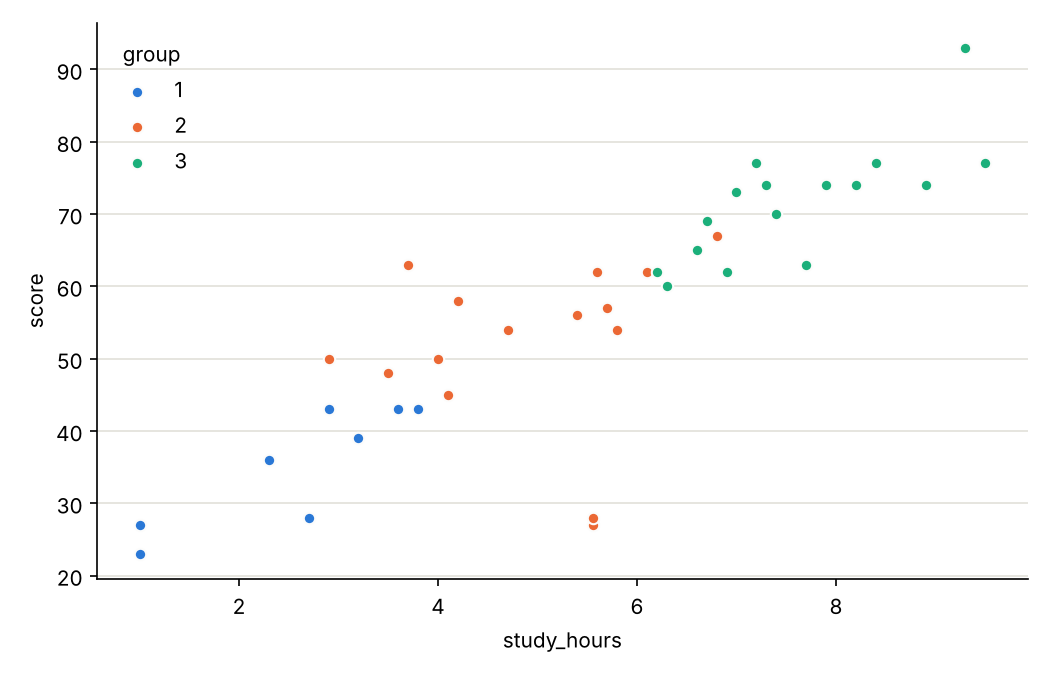

In [12]:
%%sym
marks ← ↓ "marks_clean.csv"
columns ← ["study_hours", "sleep_hours", "score"]
marks ← κ marks, columns, 3
μ marks, "group", columns
• marks, "study_hours", "score", "group"

## 13. Which column matters most for the score?

In [13]:
%%sym
marks ← ↓ "marks_clean.csv"
inputs ← ["study_hours", "sleep_hours", "attendance"]
⇅ marks, inputs, "score"

Loaded 39 rows and 6 columns from marks_clean.csv.
The answer "score" is a number with many different values, so I guess a number.
Ranked 3 columns for guessing score: study_hours matters most. A high share means the guesses lean on that column, not that it causes the answer.
     column  share (%)
study_hours         69
 attendance         25
sleep_hours          6


## 14. Which words come up most, and can it tell good reviews from bad ones?

In [14]:
%%sym
reviews ← ↓ "reviews.csv"
¶▲ reviews, "text", 10
model ← θ¶ reviews, "text", "label"
✓ model
ŷ model, "Loved it, will come again"

Loaded 40 rows and 2 columns from reviews.csv.
The 10 words used most often in text. Very common words such as the and a are left out.
         word  count
     honestly      8
        place      7
       lovely      6
         come      6
         meal      5
     friendly      5
        bland      5
   overpriced      5
disappointing      5
         cold      4
Taught a text sorter on 32 rows and tested it on 8 others.
It was right for 7 of 8.
When it said bad, it was right 3 times out of 3.
Of the rows that really were bad, it found 3 out of 4.
When it said good, it was right 4 times out of 5.
Of the rows that really were good, it found 4 out of 4.
For "Loved it, will come again" the guess is good.


## 15. Dates over time: sales for each month, drawn as a line

Loaded 240 rows and 2 columns from sales.csv.
Read 240 dates in the column date.
Added up amount for each month: 12 months, from 2025-01 to 2025-12.
Drawing a line of total against month.


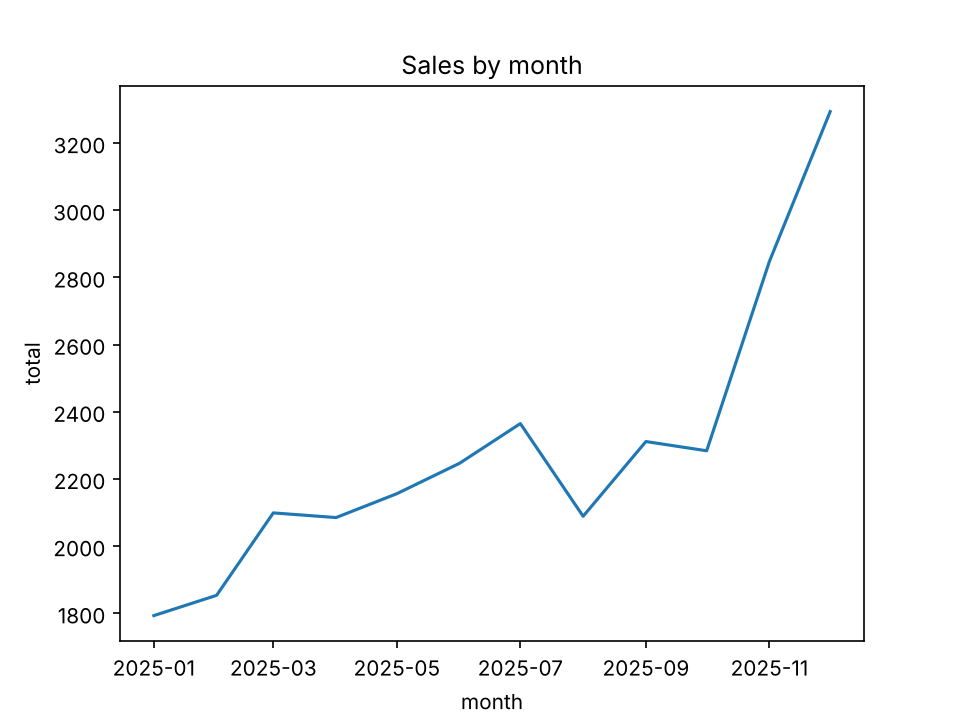

In [15]:
%%sym
sales ← ↓ "sales.csv"
sales ← ⌚ sales, "date", "d/m/y"
months ← Σ sales, "date", "amount"
~ months, "month", "total", "Sales by month"

## 16. A whole report, and a guess, one line each

Loaded 40 rows and 7 columns from marks.csv.
Step 1: look at the table.
marks: 40 rows and 7 columns.
     column    kind  missing smallest biggest average
      class   words        0                         
       year numbers        0     2025    2025    2025
study_hours numbers        2        1     9.5    5.56
sleep_hours numbers        0      4.5     8.8    6.63
 attendance numbers        0       64     100   84.12
      score numbers        0       23     999   80.15
     result   words        0                         
Step 2: clean a copy of the table. Your table is not changed.
Filled 2 gaps in study_hours with the average (5.56).
Removed 1 row where score is far from the rest (999).
Removed the column year: it is the same on every row.
Cleaned marks: 40 rows and 7 columns became 39 rows and 6 columns.
Step 3: the shape of each number column.
Drawing a histogram of study_hours.


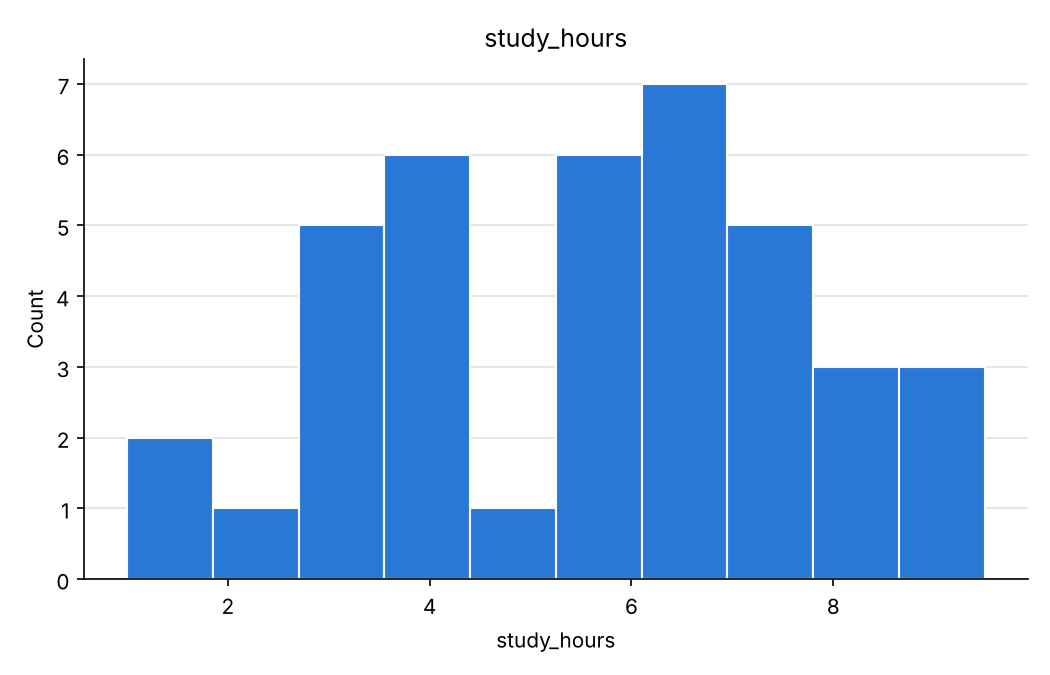

Drawing a histogram of sleep_hours.


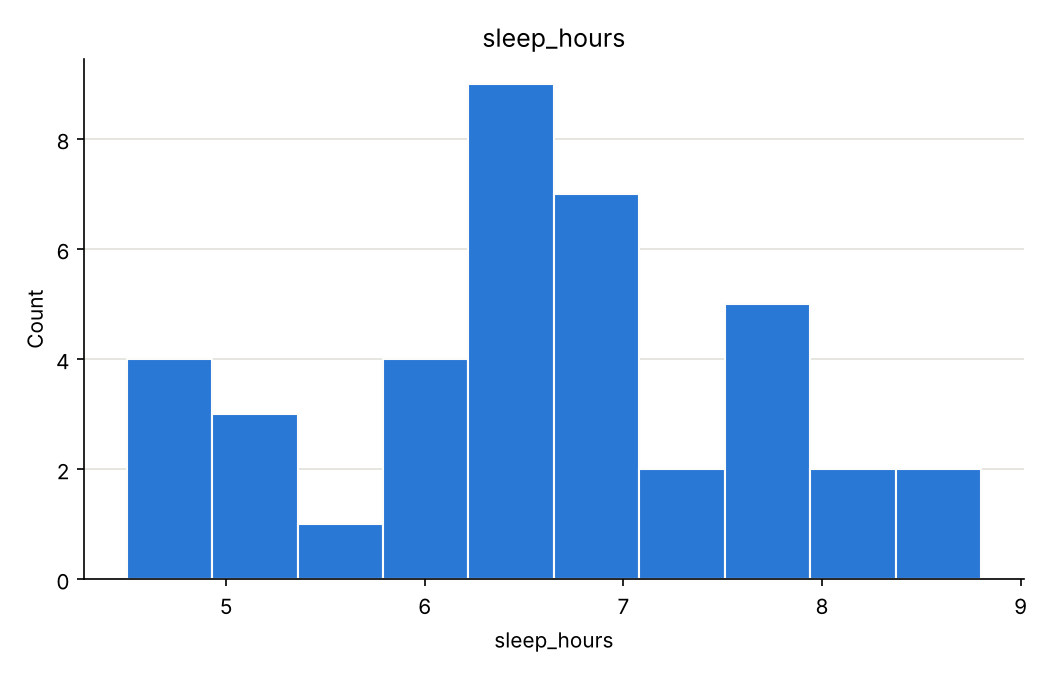

Drawing a histogram of attendance.


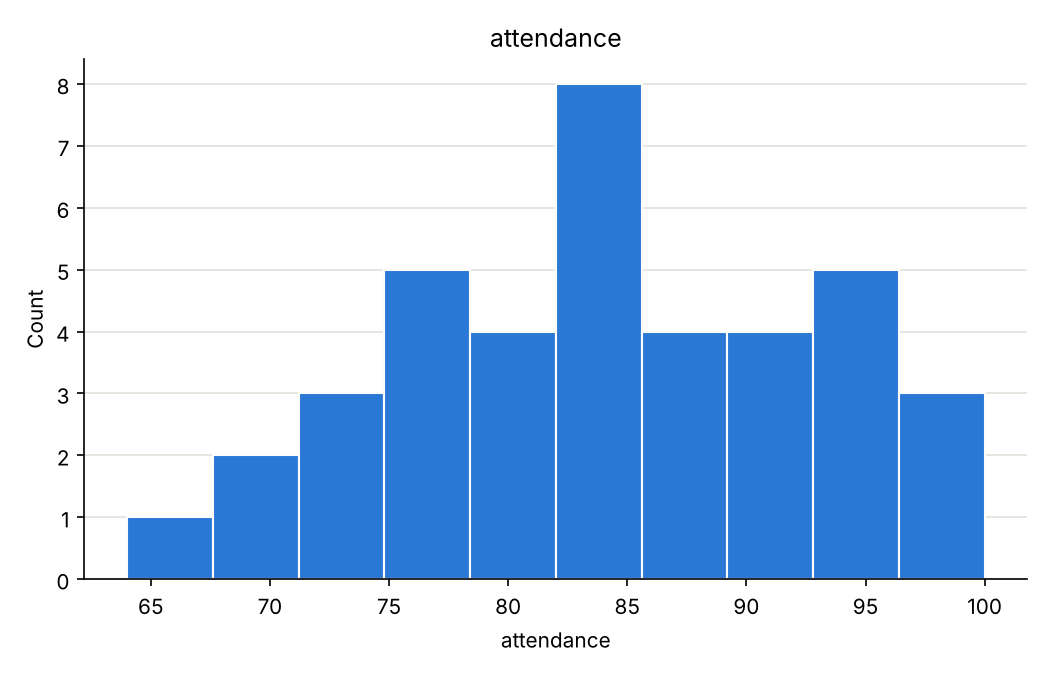

Drawing a histogram of score.


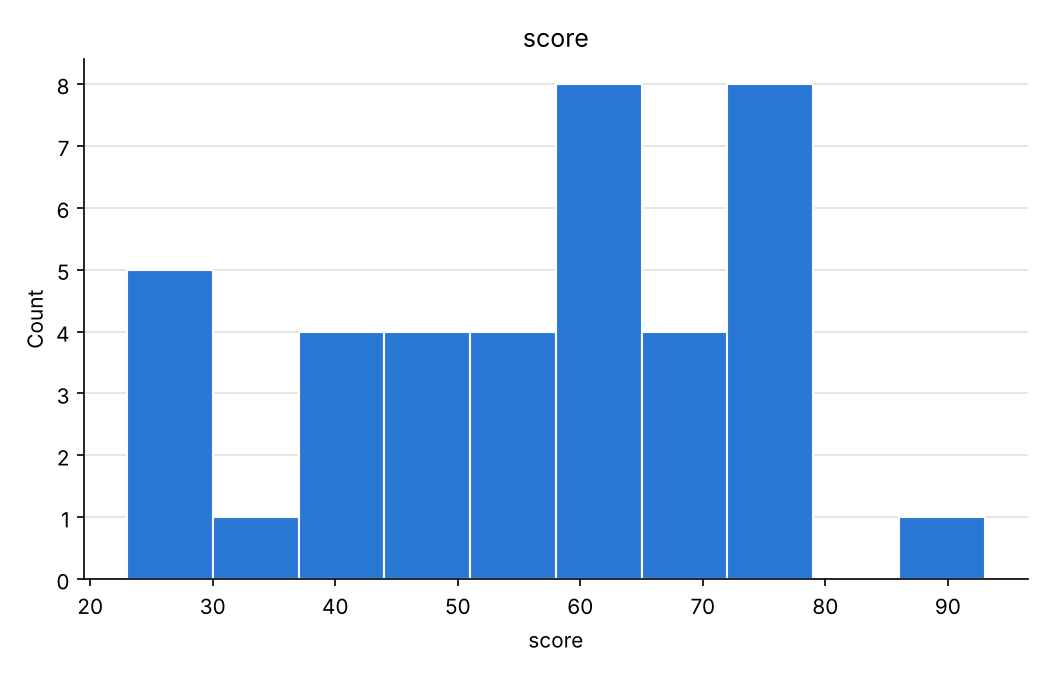

Step 4: the links between the number columns.
Drawing the links between the number columns.


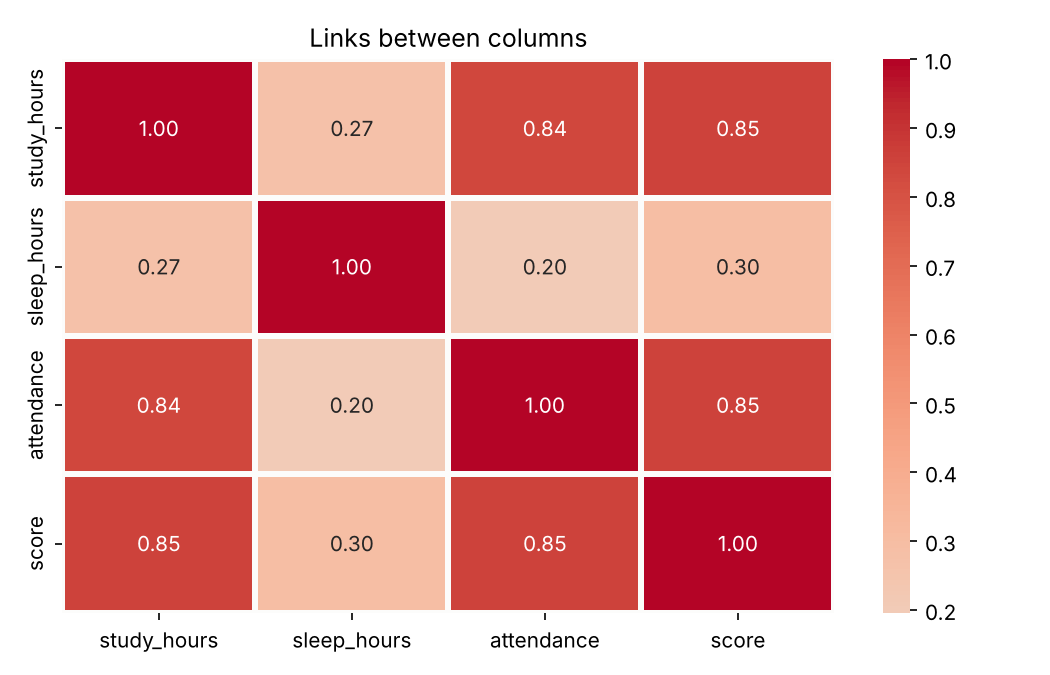

Step 1: clean a copy of the table. Your table is not changed.
Filled 2 gaps in study_hours with the average (5.56).
Removed 1 row where score is far from the rest (999).
Removed the column year: it is the same on every row.
Cleaned marks: 40 rows and 7 columns became 39 rows and 6 columns.
Step 2: choose the inputs.
Inputs used: class, study_hours, sleep_hours, attendance, result. Look for one that gives the answer away.
Step 3: teach a straight line and a random forest, and keep the better one.
The answer "score" is a number with many different values, so I guess a number.
Turned the words in class into number columns of 1 and 0: class_A, class_B, class_C.
Turned the words in result into number columns of 1 and 0: result_fail, result_pass.
Taught a straight line on 31 rows and tested it on 8 others.
Taught a random forest on 31 rows and tested it on 8 others.
Tried a straight line (share explained 66%) and a random forest (share explained 73%). Kept the random forest.
Step 4: how good

In [16]:
%%sym
marks ← ↓ "marks.csv"
⚡§ marks
⚡ŷ marks, "score"

## 17. Two ways to bring data in: a file, or a ready-made practice table

In [17]:
%%sym
marks ← ↓ "marks.csv"
marks ← ✎ "marks"

Loaded 40 rows and 7 columns from marks.csv.
Made the practice table "marks": 40 rows and 7 columns.
